# AI你画我猜：训练自己的涂鸦识别模型

人工智能通识课 · 小组大作业 · 3—4人

周末，朋友们玩“你画我猜”。有人把兔子画成了猫，有人把苹果画得像甜甜圈。**本作业以“你画我猜”为场景，训练一个能够参与游戏的涂鸦识别模型。**

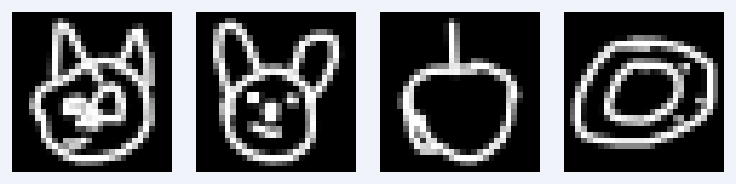

模型的输入是一格格明暗数字。小组需使用带标签的涂鸦训练模型，再通过未进入训练的图片评价表现，分析可识别的线索与常见混淆。

> **识别体验 → 观察数据 → 训练模型 → 分析结果 → 手绘图片识别 → 对照研究**

训练过程已封装，可先按顺序运行短代码单元格，再通过按钮、下拉框和滑块完成操作。需要更多参数选择时，可阅读选读B；希望实现自定义模型时，可阅读选读C。

本作业以证据分析、对照设计、AI核查与小组讨论为学习重点。基础研究路线可满足全部评分要求；准确率、模型复杂度和界面美观不单独计分。

**本Notebook分为两个阶段：**

- **第一阶段（第1—5部分）：完成第一次完整体验。** 从认识涂鸦到训练、评价模型，再用自己的图片进行识别。
- **第二阶段（第6部分）：开展新的对照实验。** 以第一次实验为参照，围绕一个研究问题修改条件，训练新模型并分析差异。

第7部分说明保存与提交。选读A、B、C提供扩展研究入口，均可按研究需要选择；完成作业仍需要有目的的对照、结果分析和过程记录。


## 0 · 打开涂鸦工作台

完整解压学生包，在Jupyter中打开本Notebook。点击下面的单元格，按 **Shift + Enter** 运行。看到绿色“工作台已启动”就可以继续；第一次安装环境请先读[实验指南](资源/使用说明.html#run)。

第一次可以逐格体验，也可以“重启内核并运行全部”看默认结果：只会训练一个小MLP。调参、CNN、挑战评价都要自己按按钮才会执行。数据已在包内，依赖安装好后无需外网。

In [1]:
import sys
sys.path.insert(0, ".")  # 读取随包程序，无需修改
from doodlelab import start_lab
lab = start_lab(root=".")

## 第一阶段 · 完成第一次训练与识别

### 1 · 涂鸦识别体验

运行下方单元格，观察涂鸦并选择类别，再点击“揭晓标注”核对原数据标签。点击“换一张”可观察其他样本。

**讨论提示：** 哪些类别容易混淆？判断依据是耳朵、尾巴、轮廓，还是其他线索？组员判断不一致时，应说明各自依据。

In [8]:
猜画面板 = lab.play()

### 2 · 观察训练数据

本作业采用八个类别：**猫、兔子、鸟、鱼、苹果、香蕉、蛋糕、甜甜圈**。下方样本来自Quick, Draw!公开涂鸦数据。可使用下拉框选择类别，观察同一类别的不同画法。

每张图是28×28灰度图，统一成“黑底亮线”。训练时，模型同时看到图和标签；评价时，模型先输出预测，程序再将预测与标签比较。

| 用途 | 本包数量 | 怎么使用 |
|---|---:|---|
| 基础训练 | 每类300张，共2400张 | 默认初始实验使用 |
| 扩展训练 | 每类3000张，共24000张 | 进阶可选，包含基础训练 |
| 基础验证 | 每类200张，共1600张 | 所有实验共同评价，不进入训练 |

训练和验证来源相近，却没有重复图像或相同原始来源。来源、固定标签和抽样记录在`资源/data/manifest.json`等文件中；标签顺序不能随意改。

**观察证据：** 同一类的画差别有多大？“猫”和“兔子”是否只靠一个特征就能区分？

In [2]:
lab.gallery()

### 3 · 训练初始模型

运行下方单元格，等待训练完成。初始模型为小型**多层感知机（MLP）**：784个像素值经过两个隐藏层，输出八个类别的分数。

训练过程中，模型比较预测与标签并更新内部参数。完整使用一遍训练集称为**一轮**。默认训练12轮，使用普通电脑CPU运行；耗时以实际设备为准。

该函数依次完成训练、评价、保存和加载一致性检查，自动创建新的实验目录。基础操作无需编写训练循环。

**讨论提示：** 训练集准确率较高，是否意味着模型也能正确识别未见过的涂鸦？

In [3]:
第一次 = lab.train("第一次训练")

### 4 · 分析训练结果与错误样例

运行下方单元格，查看曲线与错误样例。两张图分别展示损失（犯错程度）与准确率（正确识别比例）；蓝线对应训练集，橙线对应基础验证集。可展开类别表现与混淆表。

**分析提示：**

- 两条准确率曲线一起上升，还是逐渐分开？如果训练越好、验证不再改善，更多轮数可能会怎样？
- 选择两张错误样例：原图是否存在歧义？预测可能依赖哪些线索，遗漏了哪些线索？
- 总体表现是否掩盖了某一类的困难？

验证集允许查看、分析和用于调参。反复使用后的成绩仍是公开验证结果，不能称为独立测试成绩。

类别,正确数量 / 总数,准确率
猫,99 / 200,49.5%
兔子,114 / 200,57.0%
鸟,134 / 200,67.0%
鱼,185 / 200,92.5%
苹果,177 / 200,88.5%
香蕉,173 / 200,86.5%
蛋糕,156 / 200,78.0%
甜甜圈,160 / 200,80.0%

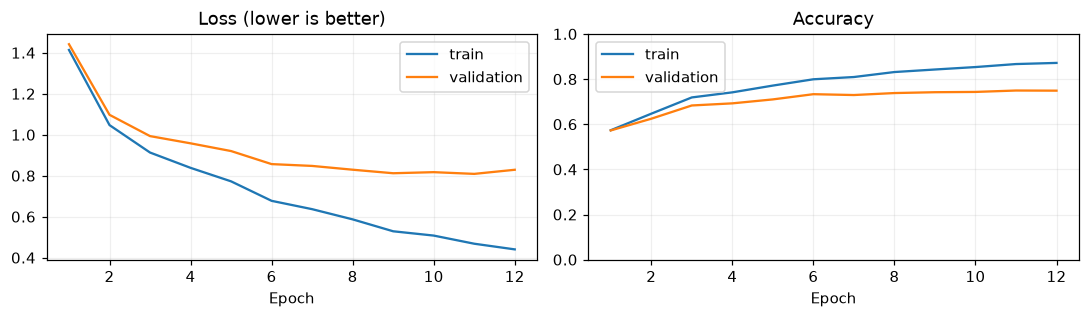
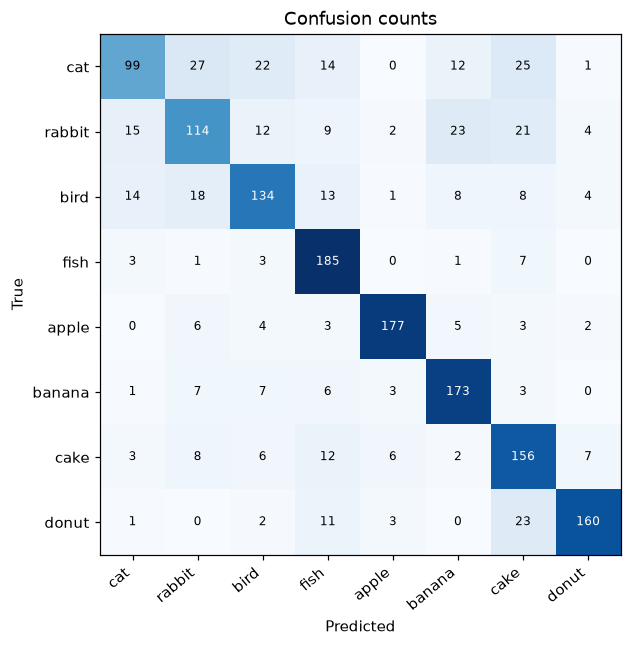

In [4]:
lab.results()

### 5 · 使用手绘图片进行识别

**本部分的任务：使用第3部分训练好的模型，识别一张新图片。** 第4部分检查它在统一验证集上的表现；本部分通过自绘图片观察外部输入的识别表现及预处理的影响。预测只使用现有模型，不会让模型继续学习这张画。

#### 第一步：查看图片识别示例

运行下方单元格，面板会自动识别一张随包的**合成画板苹果**。先找到结果中的“使用模型”，确认它是“第一次训练”，再核对以下三项内容：

| 结果 | 它说明什么？ | 应检查什么？ |
|---|---|---|
| 原图 | 提供给程序的图片 | 图案是否清楚、是否只有一个主体？ |
| 模型实际看到的28×28图 | 图片经过处理后，真正送入模型的内容 | 耳朵、轮廓等关键线索是否还在？是否裁掉了主体？ |
| 前三项预测及分数 | 模型对八个已知类别的相对评分 | 第一项是否合理？是否出现高分错误预测？ |

程序会处理透明背景、判断深浅方向、找到线条范围，再缩放并居中。画板上的白底黑线，变成28×28图中的黑底亮线，是为了与训练数据保持一致。

#### 第二步：导入自绘图片

1. 打开同目录的[离线画板](画板.html)，画八个类别中的一个图案，导出PNG图片。初次操作建议选择主体清楚的图案。
2. 将图片放入**本Notebook所在文件夹里的`my_images`文件夹**。例如，将图片命名为`my_apple.png`。
3. 回到下方面板，将“文件路径”改为`my_images/my_apple.png`，再按“让当前模型猜”。新放入的图片可以直接填写路径，无需出现在下拉列表里。
4. 检查结果中的模型名称、28×28图和预测。再导入一幅易混淆的图案，比较两次结果并记录图片文件名。

普通画板图片可以先保持“图片处理设置”的默认值。如果提示找不到文件，检查图片是否确实放在`my_images`中，以及文件名和扩展名是否一致。使用云端Notebook时，需要把图片上传到云端的同名文件夹。

<details>
<summary><b>可选：输入照片，或调整图片处理设置</b></summary>

使用白纸、深色笔、单个图案，尽量正拍并保持光照均匀。将照片放入`my_images`，填写路径，展开“图片处理设置”，把“输入类型”改为“白纸深色笔照片”。随包的纸面苹果是合成示意，不能作为真实拍摄数据。

| 设置 | 什么时候需要调整？ |
|---|---|
| 黑白方向 | 自动判断后深浅颠倒时，按原图选择“白底深色线”或“黑底亮色线” |
| 启用裁剪 | 照片包含桌面、纸边或其他物体时，仅保留图案周围区域 |
| 左、上、右、下 | 裁剪框在原图中的像素坐标；左上角是(0,0)，向右、向下增大。须满足左＜右、上＜下，并且不超出原图尺寸 |
| 找线条阈值 | 程序找出的主体范围不合适时，调整用于寻找主体边界的深浅阈值，检查是否保留完整线条 |
| 图案占几格 | 图案在28×28画面中需要放大或缩小时调整；默认最长边占26格，其余位置补黑并居中 |

可在图片查看工具或文件属性中查看原图的宽度、高度。勾选裁剪后，四个坐标都需要填写；保持默认的四个0无法形成有效裁剪框。每次调整后重新按预测按钮，比较28×28图。当前方法适用于上述输入条件，不能保证正确处理任意照片。

</details>

**记录与讨论：** 出现错误预测时，应先检查28×28图是否保留关键线索，再分析模型对这些线索的识别表现。单张图片用于观察现象，不能替代基础验证集的总体评价。模型只识别八个给定类别；类别外的图也会被分到其中之一。输出分数不代表保证正确的概率。

> **第一阶段完成训练 → 统一验证 → 新图片识别的完整流程。** 保留第一次实验的结果。接下来第6部分会从头训练另一个模型，用于检验小组提出的研究问题。


In [5]:
图片面板 = lab.image_panel()

## 第二阶段 · 开展新的对照实验

### 6 · 开展新的对照实验

**本部分的任务：以“第一次训练”为参照，开展至少一次有目的的对照实验。** 新实验会从头建立并训练一个模型，不是在第一次模型上继续学习。第5部分提供图片识别工具；它不会自动产生对照实验，也不会将外部输入图片加入训练集。

#### 第一步：提出问题，确定条件

先在小组记录里写下**研究问题、预期、准备修改的条件和保持不变的条件**，再操作面板。

例如：“减小学习率后，训练曲线是否更稳定，还是在12轮内学习不足？”可以只改“每步学习幅度”，保留轮数、模型、训练资料和随机种子。

| 研究问题 | 修改入口 | 应观察的证据 |
|---|---|---|
| 学习幅度大或小，会有什么变化？ | 每步学习幅度（lr） | 曲线是否稳定、同轮数下是否学会、错误类型 |
| 多学几遍有帮助吗？ | 完整学习轮数（epochs） | 训练与验证曲线是否分开、耗时 |
| 更大的网络一定更好吗？ | MLP两层大小（hidden_sizes） | 类别差异、错误样例、参数数量与耗时 |

这些是研究方向示例，可自行提出其他问题。基础研究路线可满足全部评分要求；CNN、扩展资料和正则化为可选研究内容。同时改变多个条件时，应说明设计理由和解释结果的局限。

#### 第二步：训练新模型

运行下方单元格打开实验面板。面板预设学习幅度0.0003，可以与第一次的0.001进行比较；如研究其他问题，请改为相应设置，并填写能够区分实验的名称。

**移动滑块只修改待执行设置。** 检查“准备执行”中的配置，再按“从头训练并保存”。完成后会显示新实验的曲线和比较表，实际参数与结果会自动保存。

> **此后的“当前模型”是最近一次成功训练或加载的模型。** 新实验完成后，当前模型就切换为新模型；第一次实验的文件仍保留。之前已经显示的曲线和图片预测保持原样，不会随模型切换自动更新。先确认每份结果上的实验名称，再进行比较。


In [ ]:
实验面板 = lab.experiment_panel()

#### 第三步：比较结果，解释差异

完成新实验后，运行下一格汇总已保存的实验。对照表用于找到差异，具体解释仍需查看曲线、类别表现和错误样例。

- **统一验证结果：** 比较第一次与新实验在同一基础验证集上的表现。需要查看新模型的完整结果时，重新运行第4部分的`lab.results()`单元格；新输出中的模型名称应与新实验一致。
- **自绘图片（可选）：** 可以回到第5部分，使用相同文件、保持相同图片处理设置，再按“让当前模型猜”。此时使用的是新模型，结果中会显示它的名称。按按钮前先记录旧预测，避免覆盖后无法比较。
- **研究结论：** 预期是否得到支持？总体准确率、某些类别和曲线是否给出一致证据？新模型准确率未提高时，也应说明对照结果支持的判断及尚未解决的问题。

核查一条与本次实验有关的关键AI建议，记录建议、验证办法和实际结果。组员观点不一致时，记录不同理由及验证过程；AI互动记录按内容与核查质量评价，不按聊天数量评价。

**需要重新查看第一次模型时：** 可使用选读B中的`lab.load(...)`加载第一次实验目录，再运行结果或图片识别功能。加载也会切换当前模型，请以输出中的实验名称为准。


In [7]:
实验记录 = lab.compare()

实验,模型,结构,学习率,轮数,训练集,种子,基础验证,训练秒数
第一次训练,mlp,"[64, 32]",0.001,12,train_basic,20261008,74.9%,2.02
学习率对照,mlp,"[64, 32]",0.0003,12,train_basic,20261008,71.2%,0.56


## 7 · 整理实验材料与提交报告

**本作业以Word实验报告为主要评分材料。** 完成第6部分的对照后，先保存Notebook，再运行下方单元格。程序默认收集第一次和当前实验，同一实验不重复收集；不会复制全部试跑。

导出目录为`提交材料/小组作业_时间/`，包含：

- `报告_请填写.docx`：使用Word填写并重命名为`小组编号_你画我猜报告.docx`。结构和格式见[任务说明](开始.html#task)，正式模板也可从[报告模板](报告模板.docx)打开。
- `实验附件/`：选定实验的文字记录、模型、关键曲线和程序。将此文件夹压缩为`小组编号_实验附件.zip`，作为报告的补充材料。
- `提交前请读.txt`：材料整理和复运行说明。

报告应呈现研究问题、对照设置、真实结果与分析、AI核查、小组讨论、成员贡献及结论局限。正文选择关键图表，无需粘贴全部日志或聊天记录；完整训练设置和结果可查阅附件中的TXT，也可将这些文字提供给AI辅助分析。

默认“运行全部”只完成一次初始实验。**须完成至少一次有目的的对照，再重新导出正式提交材料。** 每次导出均新建目录，已填写的报告不会覆盖；最终提交一份报告和一份整理好的附件。课程数据、Python环境、大量原始照片及全部Notebook输出不重复提交。

若平台仅允许上传一个文件，可将报告和实验附件合并为一个ZIP，报告放在压缩包顶层。

In [ ]:
lab.export()

## 选读 A · 它经得起画法变化吗？

挑战评价从另一批独立原图开始。原图以及它们的变换图，都没有进入任何训练集；四组各640张。三种变化共用同一组父图，适合配对比较。它们是**合成变换**，不是手绘采集或实际拍照。

| 类型 | 变化定义 | 研究方向 |
|---|---|---|
| 独立原图 | 原始涂鸦，作为配对参照 | 比较图像来源本身的差别 |
| 偏移 | 右移3格、下移2格，空位补黑，边缘可能裁掉 | 模型是否过于依赖位置？ |
| 加粗 | 3×3邻域取最大值 | 粗笔与细笔有什么差异？ |
| 遮挡 | 中央8×5格置黑 | 少一个关键部位会怎样？ |

按按钮评价**当前模型**，分别查看每种挑战和各类别。原图不保证比基础验证更难，也不保证每种变化都使成绩下降。研究抗偏移表现时，可在训练面板增加随机偏移，再与未增强的实验比较。

开展自绘图片或照片研究时，应区分用于改进方法与用于评价改进的两批样本。样本较少时，应说明证据局限。

In [ ]:
挑战面板 = lab.challenge_panel()

## 选读 B · 使用函数参数开展实验

**适用情形：** 研究需要的设置不在操作面板中，例如尝试三层MLP，或使用自选的隐藏层大小。本节沿用相同的训练、评价和保存流程，无需编写训练循环。

#### 操作方法

1. 明确研究问题和参照实验，确定本次准备改变的参数。
2. 修改下方代码单元格中的实验名与参数，删除行首的`#`，再运行。`#`表示注释；保留它时不会训练，默认“运行全部”也不会执行这些选读实验。
3. 查看训练完成后的实验名和保存目录，再调用结果查看或比较功能，解释与参照实验的差异。

调用形式为`lab.train("实验名", 参数名=参数值)`。例如，`hidden_sizes=[96, 48, 24]`表示MLP有三个隐藏层，每层依次有96、48、24个单元。**没有填写的参数采用程序默认值，不继承实验面板上一次的设置**；若参照实验使用了其他设置，应显式填写需要保持一致的参数。

以下为不同入口的调用示例，请选择与研究问题有关的设置，而非逐项完成：

```python
小步实验 = lab.train("小步学习", lr=0.0003, epochs=12)
三层实验 = lab.train("三层MLP", hidden_sizes=[96, 48, 24])
卷积实验 = lab.train("卷积尝试", model="cnn", channels=[8, 16])
正则实验 = lab.train("正则化对照", dropout=0.2, weight_decay=0.0001)
扩展实验 = lab.train("扩展资料对照", train_split="train_extended")
```

#### 可修改的参数

| 参数 | 含义与默认值 | 可修改范围 |
|---|---|---|
| `model` | 模型类型，`"mlp"` | `"mlp"`、`"cnn"`、`"custom"`；自定义模型见选读C |
| `hidden_sizes` | MLP各隐藏层大小，`[64,32]` | 正整数列表，可改变层数 |
| `channels` | CNN两层通道数，`[8,16]` | 恰好两个正整数；仅对CNN生效 |
| `lr`、`epochs` | 学习率0.001、轮数12 | 有限正数、正整数 |
| `batch_size`、`seed` | 每批64张、随机种子20261008 | 正整数、0—2³²−1整数 |
| `dropout`、`weight_decay` | 两项正则化，均为0 | 0≤dropout<1；有限非负weight_decay |
| `train_split`、`augment_shift` | 基础训练资料、无随机偏移 | `"train_basic"`或`"train_extended"`；0—3像素整数 |
| `custom_params` | 自定义结构参数，默认空字典 | 可保存为JSON的字典，由自定义模型构建函数解释 |

所有数据从本地加载，设备为CPU。每次调用都从头初始化模型，并在同一基础验证集上评价；训练完成后，该模型成为当前模型。控制网络和数据规模，先确认能在本组设备上运行，再安排更多实验。

#### 查看结果与复用模型

| 操作 | 示例与含义 |
|---|---|
| 查看当前模型的曲线、类别结果和错误 | `lab.results()` |
| 查看某类的错误 | `lab.errors(true_label=0, limit=8)`；0是猫，固定标签见数据记录 |
| 汇总已保存的实验 | `lab.compare()` |
| 识别本组图片 | `lab.predict("my_images/my_apple.png")`；默认按画板图片处理 |
| 加载已保存模型 | `lab.load("runs/实际实验目录名")`；替换为训练输出的真实路径，再运行结果或预测功能 |
| 评价挑战类型 | `lab.challenge()`；沿用选读A的评价规则 |

`lab.train`返回一个`Experiment`实验对象。需要进一步处理结果时，可访问`.model`（模型）、`.result`（配置和逐轮指标）、`.evaluations`（评价结果）和`.path`（保存目录）。`lab.predict`返回含前三项标签、分数和预处理图的字典。完整接口说明见[实验指南](资源/使用说明.html)。


In [ ]:
# 我的实验 = lab.train("三层MLP对照", hidden_sizes=[96, 48, 24])

## 选读 C · 实现自定义模型

**适用情形：** 本组希望研究现有MLP、CNN之外的结构，并具备编写PyTorch模型的能力。本节提供自定义模型入口；只使用面板或选读B，也可以完成全部基础作业要求。

#### 修改入口与运行步骤

1. 打开[资源/doodlelab/custom_model.py](资源/doodlelab/custom_model.py)，修改`build_custom_model(params, num_classes)`函数。`params`接收小组定义的结构参数；`num_classes`由程序传入，本作业为8。函数应返回构建好的PyTorch模型。
2. 保存源文件，**重启Notebook内核**，重新运行第0部分的工作台启动单元格。这样可确保程序读取修改后的代码。
3. 在下方单元格中删除行首`#`，用`model="custom"`选择自定义入口，并填写与模型实现一致的`custom_params`。运行后，检查训练与验证结果，再开展正式对照。

```python
自己的实验 = lab.train("自定义模型对照", model="custom", custom_params={"width":48})
```

源文件已提供可运行的小MLP示例，`width`在该示例中表示第一隐藏层大小。如果替换模型，可自行定义其他参数，并说明每个参数的含义。训练、评价、保存、加载和图片预测将共用这一模型构建入口。

#### 自定义模型必须遵守的约定

| 项目 | 要求与原因 |
|---|---|
| 输入 | `float32 [B,1,28,28]`，范围0—1，黑底亮线。B表示本批图片数量；应支持不同B值，包括单张图片预测 |
| 标签 | 整数0—7，类别顺序由`资源/data/manifest.json`固定，以保证不同模型的结果可比较 |
| 输出 | `[B,8]`原始分数（logits），模型末层不加softmax；共同训练函数会按此格式计算损失 |
| 返回对象 | CPU上的`torch.nn.Module`；模型构建函数负责建立结构，训练由共同训练循环完成 |
| 结构参数 | 可保存为JSON；相同参数应能重建相同结构，以便恢复权重。随机权重初始化由公共训练流程按种子控制 |
| 保存与加载 | 自定义模型的实验目录保留`source/doodlelab/custom_model.py`快照。修改过自定义结构后，如需加载旧实验，先恢复该实验的`custom_model.py`并重启内核；结构和源码须与权重对应 |

先验证模型能完成一次训练、保存、加载和单张图片预测，再与参照实验比较。报告中说明结构、参数与设计理由；结构更复杂本身不构成加分依据。

<details>
<summary><b>进一步修改：源码分工与底层函数接口</b></summary>

`studio.py`组织实验流程，`panels.py`提供操作面板，`core.py`实现数据加载、训练、评价、图片处理与保存，`plots.py`绘图，`custom_model.py`提供自定义结构。一般替换模型只需修改`custom_model.py`。

若研究需要修改公共流程，可阅读并替换相应底层函数。此时需保留统一的数据、标签、预处理和结果格式，并自行验证训练、保存、加载与预测是否仍可衔接。

| 底层函数 | 输入 → 返回 |
|---|---|
| `load_dataset(data_dir, split)` | 本地目录和划分名 → DatasetBundle，含x `[N,1,28,28]`、y `[N]`、标签与来源 |
| `build_model(config)` | 配置字典 → CPU模型；按seed初始化，支持mlp/cnn/custom |
| `train_model(model, train_data, val_data, config)` | 新模型与训练/验证数据 → `(model, result)`；默认12轮，保留末轮 |
| `evaluate_model(model, dataset)` | 模型与数据 → 总体/每类结果、混淆矩阵、逐图分数和错误索引 |
| `preprocess_image(image, mode="drawing", crop=None)` | 路径/PIL/uint8数组 → 原图、28×28图、tensor `[1,1,28,28]`和处理记录 |
| `predict_image(model, image, labels=...)` | 模型与图 → 标签、分数、预处理图；加载模型时自带标签 |
| `save_experiment(path, model, result, evaluations)` | 新目录与结果 → 保存目录，不覆盖旧实验 |
| `load_model(path)` | 实验目录 → `(CPU模型, metadata)`，读取配置并重建相同结构 |


详细输入范围、默认行为和调用示例见[实验指南中的接口说明](资源/使用说明.html)。修改公共流程后，应在报告中说明与原流程的差异及对比较的影响。

</details>


In [ ]:
# 自己的实验 = lab.train("自己的模型", model="custom", custom_params={"width":48})